In [32]:
import sys, os, warnings
import numpy as np
import pandas as pd
import xarray as xr
from datetime import datetime

from utils.post_process import merge_bursts
from seasonal_burst.exhaustive_search import exhaustive_search_intra_period
import utils_notebook as utils

import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots


import matplotlib.cm as cm
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
import matplotlib.colors as mcolors



import seaborn as sns
import random


In [33]:
def has_k_consecutive_above_threshold(arr, threshold, k):
    above_threshold = arr > threshold
    return np.any(np.convolve(above_threshold, np.ones(3, dtype=int), mode='valid') == k)

In [34]:
def sig_test(burst_set, start_year = 1975, end_year = 2023, N = 10000, lag=14, excludes = [1997]):
    ts_dates_normalized = ts_date_days.to_numpy().astype('datetime64[D]')
    date_to_index = {date: idx for idx, date in enumerate(ts_dates_normalized)}

    origin_sum = np.add.reduce(burst_set[f"mortality_{lag}"])

    
    burst_dates = burst_set['date'].dt.floor('D').to_numpy().astype('datetime64[D]')
    indices = np.array([date_to_index.get(date) for date in burst_dates])
    # Remove invalid indices (if any)
    valid_mask = indices != None
    valid_indices = indices[valid_mask]
    # Prepare for simulation
    valid_burst_dates = burst_dates[valid_mask]
    day_month_pairs = pd.to_datetime(valid_burst_dates).strftime('%m-%d').tolist()
    years = np.arange(start_year, end_year+1)

    for year in excludes:
        if year in years:
            years = np.delete(years, np.where(years==year)[0][0])
        
    
    count = 0
    for i in range(N):
        rsum = 0.0
        for dm in day_month_pairs:
            ryear = random.choice(years)
            rdate = np.datetime64(f"{ryear}-{dm}", 'D')
            ind = date_to_index.get(rdate)
            if ind is not None:
                rsum += np.add.reduce(ts_mort_4[ind:ind+lag])
        if rsum >= origin_sum:
            count += 1

    return count, count / N

In [35]:
def bootstrap_diff_confidence_interval(burst_set, ts_date_days, ts_mort_4, num_bootstrap=10000, ci=95, start_year = 1975, end_year = 2023, lag=14):
    # Normalize date array
    ts_dates_normalized = ts_date_days.to_numpy().astype('datetime64[D]')
    date_to_index = {date: idx for idx, date in enumerate(ts_dates_normalized)}

    burst_dates = burst_set['date'].dt.floor('D').to_numpy().astype('datetime64[D]')
    years = np.arange(start_year, end_year+1)
    if start_year <= 1997 and end_year >= 1997:
        years = np.delete(years, np.where(years==1997)[0][0])
    n_years = len(years)
    N = len(burst_dates)
    diffs = np.zeros(N)

    for i, bdate in enumerate(burst_dates):
        ind = date_to_index[bdate]
        rate_y = np.add.reduce(ts_mort_4[ind:ind+lag])  # 14-day rate at burst year

        # Extract day and month
        month = pd.to_datetime(bdate).month
        day = pd.to_datetime(bdate).day

        rates_all_years = 0
        for y in years:
            comp_date = np.datetime64(f"{y}-{month:02}-{day:02}", 'D')
            ind_y = date_to_index.get(comp_date)
            rates_all_years += np.add.reduce(ts_mort_4[ind_y:ind_y+lag])
        
        
        avg_rate = rates_all_years / n_years
        diffs[i] = rate_y - avg_rate

    # Bootstrap: 10,000 means
    boot_means = np.array([
        np.mean(np.random.choice(diffs, size=N, replace=True))
        for _ in range(num_bootstrap)
    ])

    lower = np.percentile(boot_means, (100 - ci) / 2)
    upper = np.percentile(boot_means, 100 - (100 - ci) / 2)

    return {
        "boot_means": boot_means,
        "mean_diff": np.mean(diffs),
        f"{ci}%_CI": (lower, upper),
        "diffs": diffs.tolist()
    }

def bootstrap_diff_confidence_interval2(burst_set, ts_date_days, ts_mort_4, num_bootstrap=10000, ci=95, start_year=1975, end_year=2023, lag=14):
    # Normalize date array
    ts_dates_normalized = ts_date_days.to_numpy().astype('datetime64[D]')
    date_to_index = {date: idx for idx, date in enumerate(ts_dates_normalized)}

    burst_dates = burst_set['date'].dt.floor('D').to_numpy().astype('datetime64[D]')
    years = np.arange(start_year, end_year + 1)
    if start_year <= 1997 and end_year >= 1997:
        years = np.delete(years, np.where(years == 1997)[0][0])
    n_years = len(years)
    N = len(burst_dates)
    diffs = np.zeros(N)
    percent_increases = np.zeros(N)

    for i, bdate in enumerate(burst_dates):
        ind = date_to_index[bdate]
        rate_y = np.add.reduce(ts_mort_4[ind:ind + lag])  # 14-day rate at burst year

        # Extract day and month
        month = pd.to_datetime(bdate).month
        day = pd.to_datetime(bdate).day

        rates_all_years = 0
        for y in years:
            comp_date = np.datetime64(f"{y}-{month:02}-{day:02}", 'D')
            ind_y = date_to_index.get(comp_date)
            rates_all_years += np.add.reduce(ts_mort_4[ind_y:ind_y + lag])

        avg_rate = rates_all_years / n_years
        diffs[i] = rate_y - avg_rate
        percent_increases[i] = ((rate_y - avg_rate) / avg_rate) * 100
        #diffs[i] = percent_increases[i]
    # Bootstrap: 10,000 means

    boot_means = np.array([
        np.mean(np.random.choice(diffs, size=N, replace=True))
        for _ in range(num_bootstrap)
    ])

    lower = np.percentile(boot_means, (100 - ci) / 2)
    upper = np.percentile(boot_means, 100 - (100 - ci) / 2)

    avg_percent_increase = np.average(percent_increases)
    med_percent_increase = np.median(percent_increases)

    return {
        "boot_means": boot_means,
        "mean_diff": np.mean(diffs),
        f"{ci}%_CI": (lower, upper),
        "diffs": diffs.tolist(),
        "avg_percent_increase": avg_percent_increase,
        "med_percent_increase": med_percent_increase
    }

In [36]:
start_year = 1975
end_year = 2023
n_year = end_year - start_year + 1

len_year = 92 * 24

ds = xr.open_dataset("../../Data/Paris/wgbt_era5_Paris_1974-2023jja.nc")
ts_wbgt = ds.wbgt.values.ravel().astype(np.float64)
ts_date = pd.DatetimeIndex(ds.time.values)
ts_tas = xr.open_dataset("../../Data/Paris/ta_era5_Paris_1974-2023jja.nc").t2m.values.ravel().astype(np.float64) - 273.15
ts_mort = np.load("../../Data/mortality/death_rate_jja.npy").astype(np.float64)[(start_year-1975)*92:] * 10000

mask = (ts_date.year >= start_year) & (ts_date.year <= end_year)
ts_wbgt = ts_wbgt[mask]
ts_tas = ts_tas[mask]
ts_date = ts_date[mask]


ts_date_days = pd.date_range(f'01-Jan-{start_year}', f'31-Dec-{end_year}', freq='D')
ts_date_days = ts_date_days[ts_date_days.month.isin([6, 7, 8, 9])]


tas_yearly = np.copy(ts_tas.reshape((n_year, len_year)))
wbgt_yearly = np.copy(ts_wbgt.reshape((n_year, len_year)))
mort_yearly = np.copy(ts_mort.reshape((n_year, 92)))

In [37]:
threshold = 2.5
minimum_length = 3
maximum_length = 36

In [38]:
tas_bursts = exhaustive_search_intra_period(ts_tas, n_year, threshold, len_year, minimum_length, maximum_length)
tas_bursts_merged = merge_bursts(tas_bursts)
tas_bursts = [b for b in tas_bursts_merged if b[2] >0]

wbgt_bursts = exhaustive_search_intra_period(ts_wbgt, n_year, threshold, len_year, minimum_length, maximum_length)
wbgt_bursts_merged = merge_bursts(wbgt_bursts)
wbgt_bursts = [b for b in wbgt_bursts_merged if b[2] >0]

"""
l = []
for (s,e,z) in wbgt_bursts:
    if has_k_consecutive_above_threshold(ts_wbgt[s:e+1], 28, 3):
        l.append((s,e,z))
print(len(l), len(wbgt_bursts))
wbgt_bursts = l
l = []
for (s,e,z) in tas_bursts:
    if has_k_consecutive_above_threshold(ts_tas[s:e+1], 30, 1):
        l.append((s,e,z))
print(len(l), len(tas_bursts))
tas_bursts = l
"""
#mort_bursts = exhaustive_search_intra_period(ts_mort, n_year, 2, 92, 1, 10)
#mort_bursts_merged = merge_bursts(mort_bursts)
#mort_bursts = [b for b in mort_bursts_merged if b[2] >0]

print(f"Number of heat stress bursts {len(wbgt_bursts)}")
print(f"Number of temperature bursts {len(tas_bursts)}")

Number of heat stress bursts 39
Number of temperature bursts 73


In [39]:
grid_tas_bursts = np.zeros((n_year,len_year))
grid_wbgt_bursts = np.zeros((n_year,len_year))

for (start, end, z) in tas_bursts:
    if z > 0:
        s = start % len_year
        e = end % len_year
        year = start // len_year
        grid_tas_bursts[year, s:e+1] = 1

for (start, end, z) in wbgt_bursts:
    if z > 0:
        s = start % len_year
        e = end % len_year
        year = start // len_year
        grid_wbgt_bursts[year, s:e+1] = 1


In [40]:
data = {'date': ts_date, 'wbgt_bursts': grid_wbgt_bursts.reshape(-1,1).ravel(), 'tas_bursts': grid_tas_bursts.reshape(-1,1).ravel()}
df =  pd.DataFrame(data)
df.head(5)

,date,wbgt_bursts,tas_bursts
0,1975-06-01 00:00:00,0.0,0.0
1,1975-06-01 01:00:00,0.0,0.0
2,1975-06-01 02:00:00,0.0,0.0
3,1975-06-01 03:00:00,0.0,0.0
4,1975-06-01 04:00:00,0.0,0.0


In [41]:
mort_start_year = 1975

df = df[df['date'].dt.year >= mort_start_year]

df_daily = df.resample("D", on="date").max().reset_index().dropna()
df_daily = df_daily[df_daily['date'].dt.month.isin([6, 7, 8])]

df_daily.head(5)

,date,wbgt_bursts,tas_bursts
0,1975-06-01,0.0,0.0
1,1975-06-02,0.0,0.0
2,1975-06-03,0.0,0.0
3,1975-06-04,0.0,0.0
4,1975-06-05,0.0,0.0


In [42]:
def compute_lag_mortality(burst_set, lag, mort_start_year):
    
    ts_date_days = pd.date_range(f'01-Jan-{mort_start_year}', '31-Dec-2023', freq='D')
    ts_date_days = ts_date_days[ts_date_days.month.isin([6, 7, 8, 9])]
    ts_dates_normalized = ts_date_days.to_numpy().astype('datetime64[D]')
    date_to_index = {date: idx for idx, date in enumerate(ts_dates_normalized)}
    # Normalize burst dates
    burst_dates = burst_set['date'].dt.floor('D').to_numpy().astype('datetime64[D]')
    indices = np.array([date_to_index.get(date) for date in burst_dates])

    ind = indices[0]

    # Remove invalid indices (if any)
    valid_mask = indices != None
    valid_indices = indices[valid_mask]
    mortality_14 = np.array([np.add.reduce(ts_mort_4[i:i+lag]) for i in valid_indices])
    return mortality_14

def compute_average_lag_mortality(burst_set, lag):
    ts_dates_normalized = ts_date_days.to_numpy().astype('datetime64[D]')
    date_to_index = {date: idx for idx, date in enumerate(ts_dates_normalized)}
    years = np.arange(1975, 2024)

    burst_dates = burst_set['date'].dt.floor('D').to_numpy().astype('datetime64[D]')
    avg_mortalities = []

    for bdate in burst_dates:
        dt = pd.to_datetime(bdate)
        m = dt.month
        d = dt.day

        values = []
        for y in years:
            try:
                rdate = np.datetime64(f"{y}-{m:02}-{d:02}", 'D')
                ind = date_to_index.get(rdate)
                if ind is not None:
                    values.append(np.sum(ts_mort_4[ind:ind+lag]))
            except:
                continue

        if values:
            avg_mortalities.append(np.mean(values))
        else:
            avg_mortalities.append(np.nan)

    return np.array(avg_mortalities)

In [43]:
ts_mort_4 = np.load("../../Data/mortality/death_rate_jjas.npy").astype(np.float64) * 10000
ts_date_days = pd.date_range(f'01-Jan-{mort_start_year}', '31-Dec-2023', freq='D')
ts_date_days = ts_date_days[ts_date_days.month.isin([6, 7, 8, 9])]
df_daily['rate'] = ts_mort

burst_set_wbgt = df_daily[df_daily['wbgt_bursts'] >= 1].reset_index()
burst_set_wbgt['mortality_7'] = compute_lag_mortality( burst_set_wbgt, 7, mort_start_year)
burst_set_wbgt['mortality_14'] = compute_lag_mortality( burst_set_wbgt, 14, mort_start_year)
burst_set_wbgt['mortality_14_avr'] = compute_average_lag_mortality( burst_set_wbgt, 14)

burst_set_tas = df_daily[df_daily['tas_bursts'] >= 1].reset_index()
burst_set_tas['mortality_7'] = compute_lag_mortality( burst_set_tas, 7, mort_start_year)
burst_set_tas['mortality_14'] = compute_lag_mortality( burst_set_tas, 14, mort_start_year)
burst_set_tas['mortality_14_avr'] = compute_average_lag_mortality( burst_set_tas, 14)


In [44]:
np.mean(burst_set_tas['mortality_14'])

3.142932072978829

In [45]:
burst_set_tas

,index,date,wbgt_bursts,tas_bursts,rate,mortality_7,mortality_14,mortality_14_avr
0,388,1976-06-23,0.0,1.0,0.278402,2.475997,5.704230,3.049301
1,391,1976-06-26,0.0,1.0,0.325789,2.979213,5.928030,3.073628
2,392,1976-06-27,0.0,1.0,0.432411,3.136064,5.878876,3.066088
3,393,1976-06-28,0.0,1.0,0.402794,3.150979,5.764302,3.038059
4,394,1976-06-29,0.0,1.0,0.408717,3.230826,5.579285,3.033103
...,...,...,...,...,...,...,...,...
170,17241,2022-08-14,0.0,1.0,0.182457,1.272636,2.636501,2.556746
171,17568,2023-07-07,0.0,1.0,0.202783,1.341131,2.613131,2.927534
172,17569,2023-07-08,0.0,1.0,0.207391,1.387218,2.617739,2.918539
173,17610,2023-08-18,1.0,1.0,0.142749,1.312372,2.666187,2.578405


## WBGT

In [46]:
count, p_value = sig_test(burst_set_wbgt, mort_start_year, 2023, lag=7)
print(f"Count: {count}, p-value {p_value}")

Count: 0, p-value 0.0


Average 0.362 [0.101, 0.662] 


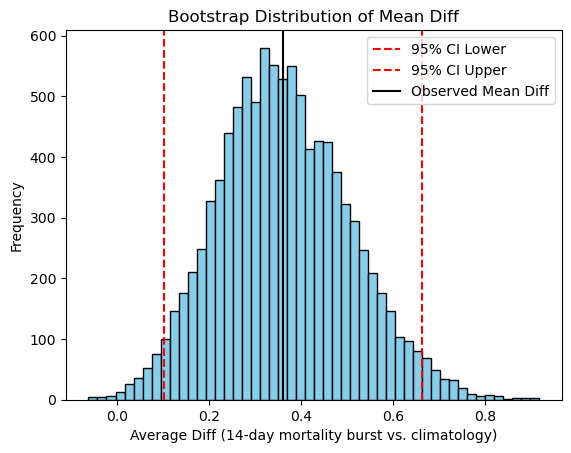

In [47]:
result = bootstrap_diff_confidence_interval(burst_set_wbgt, ts_date_days, ts_mort_4, start_year=mort_start_year)
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] " )

plt.hist(result['boot_means'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(result['95%_CI'][0], color='red', linestyle='--', label='95% CI Lower')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')
plt.axvline(result['mean_diff'], color='black', linestyle='-', label='Observed Mean Diff')
plt.legend()
plt.title('Bootstrap Distribution of Mean Diff')
plt.xlabel('Average Diff (14-day mortality burst vs. climatology)')
plt.ylabel('Frequency')
plt.show()

In [48]:
burst_set_wbgt_excl = burst_set_wbgt[burst_set_wbgt['date'].dt.year != 2003]
count, p_value = sig_test(burst_set_wbgt_excl, lag=7, excludes=[1997, 2003])
print(f"Count: {count}, p-value {p_value}")

Count: 7644, p-value 0.7644


Average -0.097 [-0.152, -0.038] -3.291% -6.061%


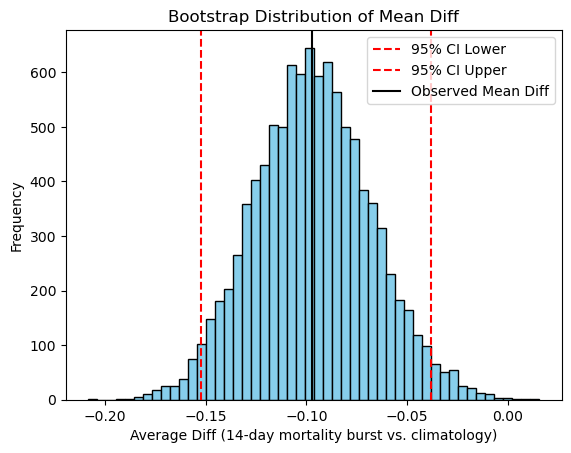

In [49]:
result = bootstrap_diff_confidence_interval2(burst_set_wbgt_excl, ts_date_days, ts_mort_4)
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] {result['avg_percent_increase']:.3f}% {result['med_percent_increase']:.3f}%" )

plt.hist(result['boot_means'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(result['95%_CI'][0], color='red', linestyle='--', label='95% CI Lower')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')
plt.axvline(result['mean_diff'], color='black', linestyle='-', label='Observed Mean Diff')
plt.legend()
plt.title('Bootstrap Distribution of Mean Diff')
plt.xlabel('Average Diff (14-day mortality burst vs. climatology)')
plt.ylabel('Frequency')
plt.show()

In [50]:
burst_set_wbgt

,index,date,wbgt_bursts,tas_bursts,rate,mortality_7,mortality_14,mortality_14_avr
0,2960,1983-07-09,1.0,0.0,0.222576,1.802324,3.496075,2.911477
1,2961,1983-07-10,1.0,0.0,0.233434,1.780610,3.420074,2.906067
2,2962,1983-07-11,1.0,0.0,0.287720,1.829468,3.349501,2.895301
3,4411,1987-06-29,1.0,0.0,0.241375,1.619097,3.166112,3.033103
4,4412,1987-06-30,1.0,0.0,0.325331,1.630296,3.145739,3.029685
...,...,...,...,...,...,...,...,...
89,17184,2022-06-18,1.0,1.0,0.218749,1.467440,2.639021,3.027026
90,17185,2022-06-19,1.0,1.0,0.227863,1.376295,2.602967,3.040074
91,17609,2023-08-17,1.0,0.0,0.216426,1.275533,2.712235,2.574300
92,17610,2023-08-18,1.0,1.0,0.142749,1.312372,2.666187,2.578405


In [51]:
df_bursts = burst_set_wbgt
print(df_bursts['mortality_14'].mean())
print(df_bursts['mortality_14'].std())
print(df_bursts['mortality_14'].median())
print(df_bursts['mortality_14'].max())
print(df_bursts['mortality_14'].min())
print(df_bursts['mortality_14'].quantile(0.95))
print(df_bursts['mortality_14'].quantile(0.99))


3.177293086809816
1.318199096787203
2.7045012656216016
7.712543849220854
2.3437275735431977
7.085474587405894
7.666159767164693


## Temperature

In [52]:
burst_set_tas

,index,date,wbgt_bursts,tas_bursts,rate,mortality_7,mortality_14,mortality_14_avr
0,388,1976-06-23,0.0,1.0,0.278402,2.475997,5.704230,3.049301
1,391,1976-06-26,0.0,1.0,0.325789,2.979213,5.928030,3.073628
2,392,1976-06-27,0.0,1.0,0.432411,3.136064,5.878876,3.066088
3,393,1976-06-28,0.0,1.0,0.402794,3.150979,5.764302,3.038059
4,394,1976-06-29,0.0,1.0,0.408717,3.230826,5.579285,3.033103
...,...,...,...,...,...,...,...,...
170,17241,2022-08-14,0.0,1.0,0.182457,1.272636,2.636501,2.556746
171,17568,2023-07-07,0.0,1.0,0.202783,1.341131,2.613131,2.927534
172,17569,2023-07-08,0.0,1.0,0.207391,1.387218,2.617739,2.918539
173,17610,2023-08-18,1.0,1.0,0.142749,1.312372,2.666187,2.578405


In [53]:
count, p_value = sig_test(burst_set_tas, lag=7)
print(f"Count: {count}, p-value {p_value}")

Count: 0, p-value 0.0


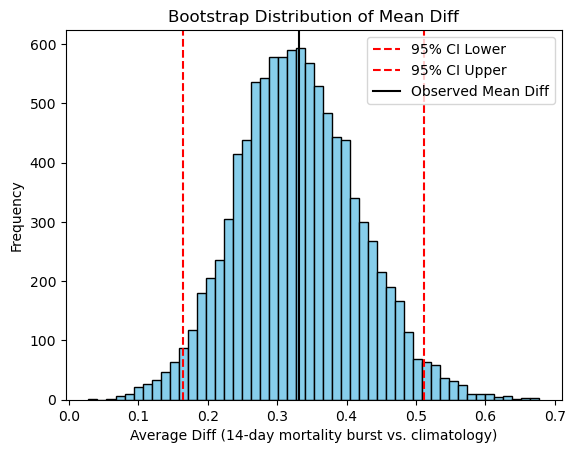

Average 0.331 [0.164, 0.511]


In [54]:
result = bootstrap_diff_confidence_interval(burst_set_tas, ts_date_days, ts_mort_4, lag=14)

plt.hist(result['boot_means'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(result['95%_CI'][0], color='red', linestyle='--', label='95% CI Lower')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')
plt.axvline(result['mean_diff'], color='black', linestyle='-', label='Observed Mean Diff')
plt.legend()
plt.title('Bootstrap Distribution of Mean Diff')
plt.xlabel('Average Diff (14-day mortality burst vs. climatology)')
plt.ylabel('Frequency')
plt.show()

print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}]")

In [55]:
burst_set_tas_excl = burst_set_tas[burst_set_tas['date'].dt.year != 2003]
count, p_value = sig_test(burst_set_tas_excl, excludes=[1997, 2003], lag=7)
print(f"Count: {count}, p-value {p_value}")

Count: 0, p-value 0.0


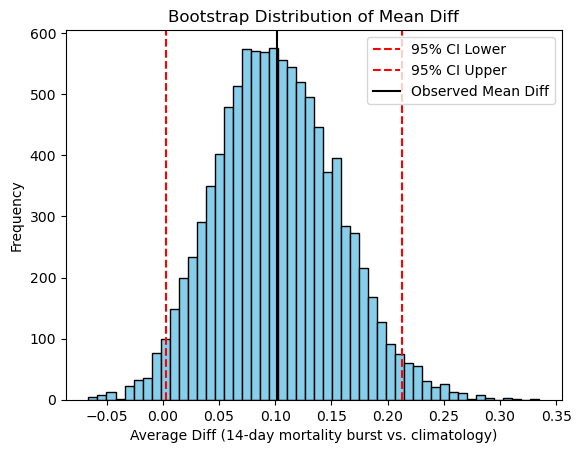

Average 0.101 [0.003, 0.213]


In [56]:
result = bootstrap_diff_confidence_interval2(burst_set_tas_excl, ts_date_days, ts_mort_4)

plt.hist(result['boot_means'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(result['95%_CI'][0], color='red', linestyle='--', label='95% CI Lower')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')
plt.axvline(result['mean_diff'], color='black', linestyle='-', label='Observed Mean Diff')
plt.legend()
plt.title('Bootstrap Distribution of Mean Diff')
plt.xlabel('Average Diff (14-day mortality burst vs. climatology)')
plt.ylabel('Frequency')
plt.show()
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}]")

Average 0.101 [0.041, 0.169]


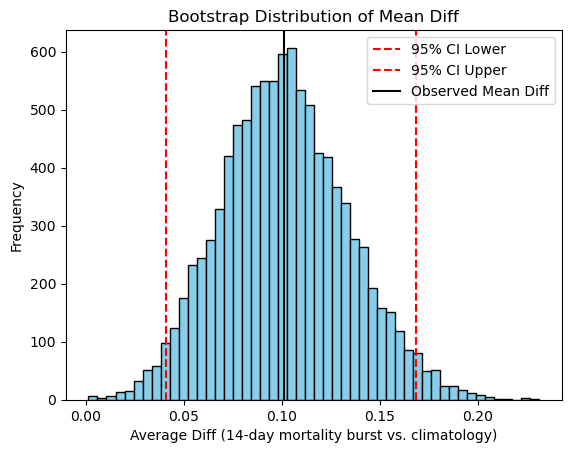

In [57]:
result = bootstrap_diff_confidence_interval2(burst_set_tas_excl, ts_date_days, ts_mort_4, lag=7)
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}]" )

plt.hist(result['boot_means'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(result['95%_CI'][0], color='red', linestyle='--', label='95% CI Lower')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')
plt.axvline(result['mean_diff'], color='black', linestyle='-', label='Observed Mean Diff')
plt.legend()
plt.title('Bootstrap Distribution of Mean Diff')
plt.xlabel('Average Diff (14-day mortality burst vs. climatology)')
plt.ylabel('Frequency')
plt.show()

In [58]:
ts_date_days

DatetimeIndex(['1975-06-01', '1975-06-02', '1975-06-03', '1975-06-04',
               '1975-06-05', '1975-06-06', '1975-06-07', '1975-06-08',
               '1975-06-09', '1975-06-10',
               ...
               '2023-09-21', '2023-09-22', '2023-09-23', '2023-09-24',
               '2023-09-25', '2023-09-26', '2023-09-27', '2023-09-28',
               '2023-09-29', '2023-09-30'],
              dtype='datetime64[ns]', length=5978, freq=None)

Average 0.274 [0.157, 0.408] 0.408%


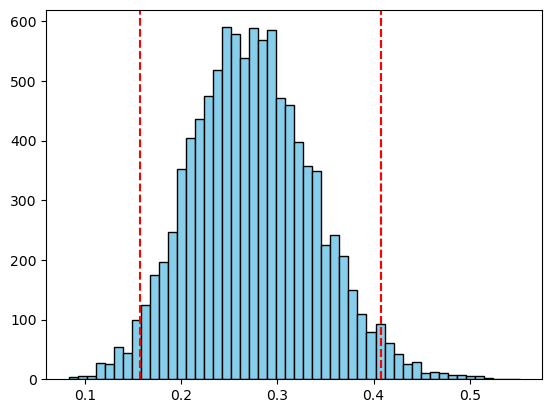

In [59]:
result = bootstrap_diff_confidence_interval2(burst_set_tas, ts_date_days, ts_mort_4, lag=7)
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] {result['95%_CI'][1]:.3f}%" )

plt.hist(result['boot_means'], bins=50, color='skyblue', edgecolor='black')
plt.axvline(result['95%_CI'][0], color='red', linestyle='--', label='95% CI Lower')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')
plt.axvline(result['95%_CI'][1], color='red', linestyle='--', label='95% CI Upper')

In [60]:
result = bootstrap_diff_confidence_interval2(burst_set_tas, ts_date_days, ts_mort_4, lag = 14)
print("Lag = 14")
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] {result['avg_percent_increase']:.3f}% {result['med_percent_increase']:.3f}%" )
print()
result = bootstrap_diff_confidence_interval2(burst_set_tas, ts_date_days, ts_mort_4, lag = 7)

print("Lag = 7")
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] {result['avg_percent_increase']:.3f}% {result['med_percent_increase']:.3f}%" )


Lag = 14
Average 0.331 [0.165, 0.514] 12.027% -3.543%

Lag = 7
Average 0.274 [0.157, 0.406] 19.488% -1.142%


In [61]:
result = bootstrap_diff_confidence_interval2(burst_set_tas_excl, ts_date_days, ts_mort_4, lag = 14)
print("Lag = 14")
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] {result['avg_percent_increase']:.3f}% {result['med_percent_increase']:.3f}%" )
print()

result = bootstrap_diff_confidence_interval2(burst_set_tas_excl, ts_date_days, ts_mort_4, lag = 7)
print("Lag = 7")
print(f"Average {result['mean_diff']:.3f} [{result['95%_CI'][0]:.3f}, {result['95%_CI'][1]:.3f}] {result['avg_percent_increase']:.3f}% {result['med_percent_increase']:.3f}%" )

Lag = 14
Average 0.101 [-0.002, 0.214] 3.305% -4.631%

Lag = 7
Average 0.101 [0.039, 0.170] 6.669% -1.494%


In [62]:
result = bootstrap_diff_confidence_interval2(burst_set_wbgt, ts_date_days, ts_mort_4, lag = 14)


In [63]:
increase = (burst_set_wbgt['mortality_14'] - burst_set_wbgt['mortality_14_avr'])/burst_set_wbgt['mortality_14_avr']*100

In [64]:
np.mean(increase), np.median(increase), np.percentile(increase, 33)

(13.268930150406698, -4.972069933581595, -7.697423155832468)